# Predicting Medicaid Coverage at the CPS-ASEC Interview

Version 2 predicts reported Medicaid coverage at the interview using [CAIDNW](https://cps.ipums.org/cps-action/variables/CAIDNW). The 2019 wave supplies training and validation data. The 2020 wave is held out for evaluation.

This analysis reconstructs the cohort from the prepared source file, before the legacy disability and Armed Forces exclusions. The original restricted-cohort notebook remains the benchmark. Both analyses use a research income screen of 138% of the federal poverty guideline among respondents aged 18–64.

## 1. Import libraries

Import the analysis tools and record package versions and the random seed.

In [1]:
import os
from itertools import combinations
from importlib.metadata import version
from pathlib import Path

import joblib
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score, brier_score_loss, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
for package in ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{package} {version(package)}")

pandas 3.1.1
numpy 2.4.6
scipy 1.17.1
scikit-learn 1.9.1
matplotlib 3.11.2


## 2. Load the source and check the label

Read the local source and restrict to ASEC interviews in 2019–2020 with valid CAIDNW codes. Keep disability and Armed Forces records. Save the original row index so the cohort can be joined to household and person groups later.

In [2]:
data_path = Path(os.environ.get("MEDICAID_ASEC_DATA", "data/Maindata1.dta"))
columns = [
    "year", "month", "asecflag", "serial", "cpsid", "cpsidp", "cpsidv",
    "asecwt", "caidnw", "diffany", "age", "statefip", "famsize", "ftotval",
    "inctot", "empstat", "health", "sex", "race", "hispan", "nativity",
    "marst", "educ", "citizen", "nchild",
]
with pd.read_stata(data_path, columns=columns, iterator=True) as reader:
    value_labels = reader.value_labels()
    raw = reader.read(convert_categoricals=False)

waves = raw.loc[raw["asecflag"].eq(1) & raw["year"].isin([2019, 2020])]
print(waves.groupby(["year", "caidnw"], dropna=False).size().unstack())
labeled = waves.loc[waves["caidnw"].isin([1, 2])].copy()
assert set(labeled["year"]) == {2019, 2020}
labeled["covered"] = labeled["caidnw"].eq(2).astype(int)

caidnw     1.0    2.0
year                 
2019    149174  30927
2020    132262  25697


## 3. Rebuild the low-income cohort

Compare prior-calendar-year family income with the HHS guideline for that income year, using family size and state at interview. CPS family income uses the Census family definition, and interview family size is an approximation for the denominator. This cutoff defines the study cohort. Valid negative incomes remain in the main analysis.

The published 2018 and 2019 schedules use constant per-person increments within each region. [HHS guideline archive](https://aspe.hhs.gov/topics/poverty-economic-mobility/poverty-guidelines/prior-hhs-poverty-guidelines-federal-register-references) · [2019 Federal Register notice](https://aspe.hhs.gov/sites/default/files/documents/713f8ce8345dc6885ed3ce441273191d/HHS-Poverty-Guidelines-Fed-Register-2019.pdf) · [IPUMS family income](https://cps.ipums.org/cps-action/variables/FTOTVAL)

In [3]:
guidelines = pd.DataFrame(
    [
        (2018, "Contiguous and DC", 12140, 4320),
        (2018, "Alaska", 15180, 5400),
        (2018, "Hawaii", 13960, 4970),
        (2019, "Contiguous and DC", 12490, 4420),
        (2019, "Alaska", 15600, 5530),
        (2019, "Hawaii", 14380, 5080),
    ],
    columns=["income_year", "region", "one_person", "additional_person"],
)

adults = labeled.loc[labeled["age"].between(18, 64)].copy()
adults["income_year"] = adults["year"] - 1
adults["region"] = adults["statefip"].map({2: "Alaska", 15: "Hawaii"})
adults["region"] = adults["region"].fillna("Contiguous and DC")
assert adults["statefip"].notna().all(), "Review missing state codes."
adults = adults.join(
    guidelines.set_index(["income_year", "region"]),
    on=["income_year", "region"], validate="many_to_one",
)
assert adults["one_person"].notna().all()

Compute the family-income ratio and show how many records pass each part of the sample screen.

In [4]:
valid_inputs = (
    adults["famsize"].ge(1)
    & adults["famsize"].mod(1).eq(0)
    & adults["ftotval"].notna()
    & adults["ftotval"].lt(9_999_999_999)
)
adults["fpl_line"] = (
    adults["one_person"] + (adults["famsize"] - 1) * adults["additional_person"]
)
adults["fpl_ratio"] = (adults["ftotval"] / adults["fpl_line"]).where(valid_inputs)
low_income = adults["fpl_ratio"].le(1.38)

print(pd.DataFrame({
    "adults_with_label": adults.groupby("year").size(),
    "valid_income_screen": valid_inputs.groupby(adults["year"]).sum(),
    "at_or_below_138_pct": low_income.groupby(adults["year"]).sum(),
}))
print("Negative family incomes retained:", adults.loc[low_income, "ftotval"].lt(0).sum())

restored = adults.loc[low_income, ["year", "diffany", "empstat"]].copy()
restored["Disability"] = restored["diffany"].eq(2)
restored["Armed Forces"] = restored["empstat"].eq(1)
display(restored.groupby("year")[["Disability", "Armed Forces"]].sum())

      adults_with_label  valid_income_screen  at_or_below_138_pct
year                                                             
2019             106576               106576                19087
2020              92618                92618                14979
Negative family incomes retained: 57


,Disability,Armed Forces
year,,
2019,2940,53
2020,2280,54


## 4. Prevent household and person overlap

Link records sharing a known CPS household ID, a person ID, or the same year, month, and household serial. Connected components keep indirect links together. Form the groups on all labeled ages before joining them to the study cohort, so an ineligible family member can still provide a link. Nonpositive IDs are treated as unavailable.

`CPSID` links households, `CPSIDP` links persons, and `CPSIDV` applies demographic validation to person links. Using both person identifiers conservatively keeps ambiguous links in the same partition.

In [5]:
labeled["wave_serial"] = (
    labeled["year"].astype(str) + "-" + labeled["month"].astype(str)
    + "-" + labeled["serial"].astype(str)
)
labeled.loc[~labeled["serial"].gt(0), "wave_serial"] = None
link_fields = ["wave_serial", "cpsid", "cpsidp", "cpsidv"]
people = len(labeled)
left_edges = []
right_edges = []
next_id = people

for field in link_fields:
    values = labeled[field]
    if field != "wave_serial":
        values = values.where(values.gt(0))
    codes, identifiers = pd.factorize(values)
    known = codes >= 0
    left_edges.append(np.flatnonzero(known))
    right_edges.append(next_id + codes[known])
    next_id += len(identifiers)

left = np.concatenate(left_edges)
right = np.concatenate(right_edges)
graph = coo_matrix(
    (np.ones(len(left), dtype=bool), (left, right)),
    shape=(next_id, next_id),
)
_, components = connected_components(graph.tocsr(), directed=False)
labeled["split_group"] = components[:people]

Attach each component to the cohort by the original source row index. Check availability of all four grouping keys.

In [6]:
adults["split_group"] = labeled["split_group"].reindex(adults.index)
adults["wave_serial"] = labeled["wave_serial"].reindex(adults.index)
assert adults["split_group"].notna().all()
cohort = adults.loc[low_income].copy()

missing_ids = {"wave_serial": cohort["wave_serial"].isna().sum()}
for field in ["cpsid", "cpsidp", "cpsidv"]:
    missing_ids[field] = (~cohort[field].gt(0)).sum()
print("Unavailable grouping IDs:", missing_ids)

Unavailable grouping IDs: {'wave_serial': np.int64(0), 'cpsid': np.int64(0), 'cpsidp': np.int64(0), 'cpsidv': np.int64(0)}


## 5. Hold out 2020 and split 2019 by group

Remove 2019 groups linked to the 2020 cohort. Split the remaining 2019 groups into training and validation, then assert that all partitions have two outcome classes and disjoint groups. The 2020 interview wave may differ from 2019 because of [pandemic-related survey nonresponse](https://www.census.gov/content/dam/Census/library/working-papers/2020/demo/sehsd-wp2020-10.pdf).

The Census Bureau suspended in-person interviewing and found selective nonresponse in 2020. This makes the holdout an important test of performance across years. The observed score change alone cannot identify the contribution of COVID-19.

In [7]:
test = cohort.loc[cohort["year"].eq(2020)].copy()
earlier = cohort.loc[cohort["year"].eq(2019)].copy()
development = earlier.loc[~earlier["split_group"].isin(test["split_group"])]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_index, val_index = next(splitter.split(development, groups=development["split_group"]))
train = development.iloc[train_index].copy()
validation = development.iloc[val_index].copy()

partitions = {"Train": train, "Validation": validation, "Test": test}
assert sum(frame["split_group"].nunique() for frame in partitions.values()) == (
    pd.concat(partitions.values())["split_group"].nunique()
)
assert all(frame["covered"].nunique() == 2 for frame in partitions.values())
print("2019 rows purged for 2020 overlap:", len(earlier) - len(development))
display(pd.DataFrame({
    name: {"Records": len(frame), "Groups": frame["split_group"].nunique()}
    for name, frame in partitions.items()
}).T)

2019 rows purged for 2020 overlap: 3285


,Records,Groups
Train,11855,7795
Validation,3947,2599
Test,14979,9907


## 6. Define predictors and explore the training data

Use interview demographics, employment, health, residence, and family composition. Prior-year personal income enters only in a validation comparison. Other coverage fields, IDs, weights, and year stay outside the feature matrix. IPUMS defines employment status from the [week before interview](https://cps.ipums.org/cps-action/variables/EMPSTAT).

Other insurance variables can encode the same outcome. Prior-year Medicaid coverage could be available in a separate use case that assumes a known coverage history. That history stays outside this model.

In [8]:
categorical = [
    "statefip", "empstat", "health", "sex", "race", "hispan",
    "nativity", "marst", "educ", "citizen",
]
numerical = ["age", "famsize", "nchild"]
for frame in partitions.values():
    frame["inctot"] = frame["inctot"].where(frame["inctot"].ne(999_999_999))

print("Training coverage rate:", train["covered"].mean().round(4))
print(train.groupby("empstat")["covered"].agg(["size", "mean"]).round(4))
print(train[categorical + numerical + ["inctot"]].isna().sum())

Training coverage rate: 0.4044
         size    mean
empstat              
1          36  0.0000
10       5280  0.3227
12        185  0.4108
21        585  0.4872
22         50  0.5600
32       1750  0.6143
34       3236  0.4305
36        733  0.3179
statefip    0
empstat     0
health      0
sex         0
race        0
hispan      0
nativity    0
marst       0
educ        0
citizen     0
age         0
famsize     0
nchild      0
inctot      0
dtype: int64


## 7. Preprocess within each model pipeline

Impute missing values and one-hot encode categories using training data. Scale numeric predictors for logistic regression. Histogram Gradient Boosting receives dense inputs.

In [9]:
def make_pipeline(estimator, numeric_fields):
    dense = isinstance(estimator, HistGradientBoostingClassifier)
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if isinstance(estimator, LogisticRegression):
        numeric_steps.append(("scale", StandardScaler()))
    preprocess = ColumnTransformer([
        ("category", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=not dense)),
        ]), categorical),
        ("number", Pipeline(numeric_steps), numeric_fields),
    ])
    return Pipeline([("preprocess", preprocess), ("model", estimator)])

## 8. Fit and tune models on 2019

Compare a prevalence baseline, logistic regression, Random Forest, and Histogram Gradient Boosting. Select by validation ROC-AUC, using Brier score as the tie-breaker. Boosting uses a fixed iteration count to avoid an internal random validation split.

In [10]:
model_grids = {
    "Prevalence": (DummyClassifier, {"strategy": ["prior"]}),
    "Logistic regression": (LogisticRegression, {"C": [0.1, 1.0], "max_iter": [1000]}),
    "Random forest": (RandomForestClassifier, {
        "n_estimators": [150], "min_samples_leaf": [10, 30],
        "n_jobs": [-1], "random_state": [SEED],
    }),
    "Histogram gradient boosting": (HistGradientBoostingClassifier, {
        "max_iter": [150], "max_leaf_nodes": [15, 31],
        "learning_rate": [0.07], "early_stopping": [False], "random_state": [SEED],
    }),
}

results = []
for name, (estimator_class, grid) in model_grids.items():
    for parameters in ParameterGrid(grid):
        model = make_pipeline(estimator_class(**parameters), numerical)
        model.fit(train, train["covered"])
        probability = model.predict_proba(validation)[:, 1]
        results.append({
            "name": name, "parameters": parameters, "model": model,
            "roc_auc": roc_auc_score(validation["covered"], probability),
            "brier": brier_score_loss(validation["covered"], probability),
        })

ranking = pd.DataFrame(results).sort_values(["roc_auc", "brier"], ascending=[False, True])
display(ranking.drop(columns="model").round(4))

,name,parameters,roc_auc,brier
6,Histogram gradient boosting,"{'early_stopping': False, 'learning_rate': 0.07, 'max_iter': 150, 'max_leaf_nodes': 31, 'random_state': 42}",0.7710,0.1894
5,Histogram gradient boosting,"{'early_stopping': False, 'learning_rate': 0.07, 'max_iter': 150, 'max_leaf_nodes': 15, 'random_state': 42}",0.7697,0.1904
3,Random forest,"{'min_samples_leaf': 10, 'n_estimators': 150, 'n_jobs': -1, 'random_state': 42}",0.7563,0.2000
2,Logistic regression,"{'C': 1.0, 'max_iter': 1000}",0.7555,0.1952
1,Logistic regression,"{'C': 0.1, 'max_iter': 1000}",0.7552,0.1956
4,Random forest,"{'min_samples_leaf': 30, 'n_estimators': 150, 'n_jobs': -1, 'random_state': 42}",0.7451,0.2063
0,Prevalence,{'strategy': 'prior'},0.5000,0.2397


### Prior-year income sensitivity

Compare the selected model with an otherwise identical model that adds personal income. Income describes the previous calendar year and can be useful when available. The interview-time specification remains primary.

In [11]:
selected = ranking.iloc[0]
final_model = selected["model"]
income_model = make_pipeline(clone(final_model.named_steps["model"]), numerical + ["inctot"])
income_model.fit(train, train["covered"])
income_probability = income_model.predict_proba(validation)[:, 1]

income_comparison = pd.DataFrame({
    "Without prior-year income": [selected["roc_auc"], selected["brier"]],
    "With prior-year income": [
        roc_auc_score(validation["covered"], income_probability),
        brier_score_loss(validation["covered"], income_probability),
    ],
}, index=["ROC-AUC", "Brier score"]).T
display(income_comparison.round(4))

,ROC-AUC,Brier score
Without prior-year income,0.7710,0.1894
With prior-year income,0.7719,0.1884


## 9. Choose the threshold

Evaluate candidate thresholds on 2019 validation. Choose the threshold with the highest balanced accuracy, with ties going to the lower threshold.

In [12]:
validation_probability = final_model.predict_proba(validation)[:, 1]
thresholds = np.arange(0.05, 1.0, 0.05)
scores = [
    balanced_accuracy_score(validation["covered"], validation_probability >= cutoff)
    for cutoff in thresholds
]
threshold = float(thresholds[np.argmax(scores)])
print(f"Selected model: {selected['name']}")
print(f"Validation-selected threshold: {threshold:.2f}")

Selected model: Histogram gradient boosting
Validation-selected threshold: 0.35


### Check partition overlap

Verify each pair shares zero grouping keys or connected components. Unknown IDs are ignored in this check because they cannot establish a link.

In [13]:
overlap_rows = []
for (left_name, left_frame), (right_name, right_frame) in combinations(partitions.items(), 2):
    row = {"Partitions": f"{left_name} / {right_name}"}
    for field in ["split_group", "wave_serial", "cpsid", "cpsidp", "cpsidv"]:
        left_ids = left_frame[field].dropna()
        right_ids = right_frame[field].dropna()
        if field not in {"split_group", "wave_serial"}:
            left_ids = left_ids[left_ids.gt(0)]
            right_ids = right_ids[right_ids.gt(0)]
        row[field] = len(set(left_ids) & set(right_ids))
    overlap_rows.append(row)

overlap = pd.DataFrame(overlap_rows).set_index("Partitions")
assert overlap.eq(0).all().all()
display(overlap)

,split_group,wave_serial,cpsid,cpsidp,cpsidv
Partitions,,,,,
Train / Validation,0,0,0,0,0
Train / Test,0,0,0,0,0
Validation / Test,0,0,0,0,0


### Measure permutation importance on validation

Shuffle one predictor at a time and measure the decrease in ROC-AUC. State can capture policy, administration, and enrollment differences. Family composition, employment, and health may provide predictive information. These scores describe how the fitted model uses each input. A low score can result when predictors carry overlapping information, and the scores do not establish causal effects.

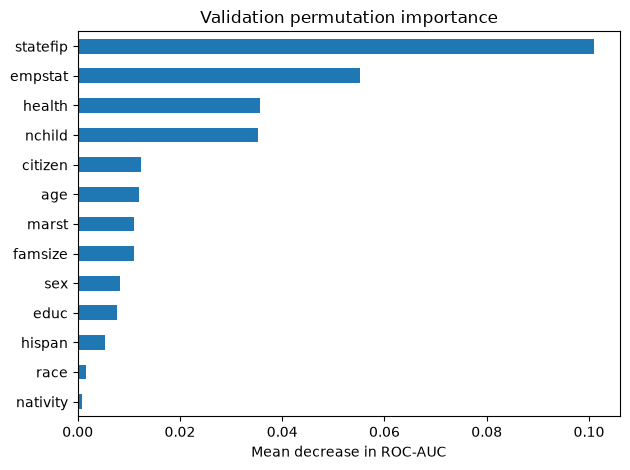

In [14]:
features = categorical + numerical
importance = permutation_importance(
    final_model, validation[features], validation["covered"],
    scoring="roc_auc", n_repeats=5, random_state=SEED,
)
importance_scores = pd.Series(importance.importances_mean, index=features)
importance_scores.sort_values().plot.barh(
    title="Validation permutation importance",
    xlabel="Mean decrease in ROC-AUC",
)
plt.tight_layout()
plt.show()

## 10. Evaluate the fixed model on 2020

Evaluate once using the model and threshold selected in 2019. Compare unweighted results with an ASEC person-weighted evaluation and check sensitivity to excluding negative family incomes or Armed Forces records from the evaluation. The calibration curve compares predicted probabilities with observed coverage.

In [15]:
def evaluate(outcome, probability, sample_weight=None):
    prediction = probability >= threshold
    return {
        "ROC-AUC": roc_auc_score(outcome, probability, sample_weight=sample_weight),
        "Precision": precision_score(outcome, prediction, sample_weight=sample_weight, zero_division=0),
        "Recall": recall_score(outcome, prediction, sample_weight=sample_weight, zero_division=0),
        "F1": f1_score(outcome, prediction, sample_weight=sample_weight, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(outcome, prediction, sample_weight=sample_weight),
        "Brier score": brier_score_loss(outcome, probability, sample_weight=sample_weight),
    }

test_probability = final_model.predict_proba(test)[:, 1]
weighted = test["asecwt"].gt(0) & np.isfinite(test["asecwt"])
nonnegative = test["ftotval"].ge(0)
civilian = test["empstat"].ne(1)
assert test.loc[weighted, "covered"].nunique() == 2
test_results = pd.DataFrame({
    "All eligible test records": evaluate(test["covered"], test_probability),
    "ASEC-weighted test": evaluate(
        test.loc[weighted, "covered"], test_probability[weighted], test.loc[weighted, "asecwt"]
    ),
    "Civilian test subset": evaluate(
        test.loc[civilian, "covered"], test_probability[civilian]
    ),
    "Nonnegative family income": evaluate(
        test.loc[nonnegative, "covered"], test_probability[nonnegative]
    ),
}).T
display(test_results.round(4))

,ROC-AUC,Precision,Recall,F1,Balanced accuracy,Brier score
All eligible test records,0.7429,0.5709,0.7785,0.6588,0.6751,0.2021
ASEC-weighted test,0.7544,0.5684,0.7800,0.6576,0.6892,0.1960
Civilian test subset,0.7413,0.5709,0.7785,0.6588,0.6738,0.2029
Nonnegative family income,0.7428,0.5711,0.7784,0.6589,0.6751,0.2022


Check how closely the selected model’s estimated probabilities match observed Medicaid coverage in the held-out year.

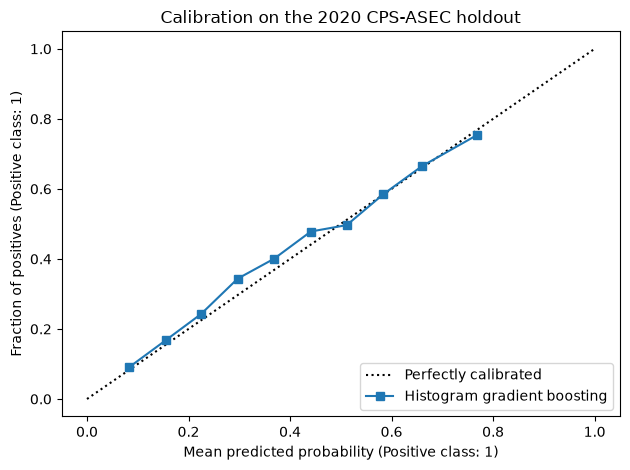

In [16]:
CalibrationDisplay.from_predictions(
    test["covered"], test_probability, n_bins=10, strategy="quantile",
    name=selected["name"],
)
plt.title("Calibration on the 2020 CPS-ASEC holdout")
plt.tight_layout()
plt.show()

## 11. Final results and interpretation

Review validation model comparisons and the performance of the frozen model on the 2020 holdout. The summary below uses the results computed in this run.

In [17]:
best_by_model = ranking.drop_duplicates("name").set_index("name")
test_summary = test_results.loc["All eligible test records"]
test_rate = test["covered"].mean()
mean_forecast = test_probability.mean()
leading_features = ", ".join(importance_scores.nlargest(5).index)
auc_change = test_summary["ROC-AUC"] - selected["roc_auc"]

display(Markdown(f"""
### Model comparison and out-of-year performance

{selected['name']} led 2019 validation with ROC-AUC **{selected['roc_auc']:.4f}**.
Logistic Regression reached **{best_by_model.loc['Logistic regression', 'roc_auc']:.4f}**
and Random Forest reached **{best_by_model.loc['Random forest', 'roc_auc']:.4f}**.
The 2020 ROC-AUC was **{test_summary['ROC-AUC']:.4f}** ({auc_change:+.4f} from validation).
ROC-AUC measures how well the model ranks people with reported coverage above those without it.

### Classification at the validation threshold

At **{threshold:.2f}**, **{test_summary['Precision']:.1%}** of positive predictions
were recorded as covered and the model identified **{test_summary['Recall']:.1%}**
of covered respondents. F1, the harmonic mean of precision and recall, was
**{test_summary['F1']:.4f}**. Balanced accuracy, the average of sensitivity and
specificity, was **{test_summary['Balanced accuracy']:.4f}**.

### Calibration and predictors

The mean predicted probability was **{mean_forecast:.1%}**, compared with an
observed coverage rate of **{test_rate:.1%}**. The calibration curve shows where
probabilities diverge across the range. The Brier score, mean squared probability
error, was **{test_summary['Brier score']:.4f}**. The five highest validation
permutation scores were for **{leading_features}**.
"""))


### Model comparison and out-of-year performance

Histogram gradient boosting led 2019 validation with ROC-AUC **0.7710**.
Logistic Regression reached **0.7555**
and Random Forest reached **0.7563**.
The 2020 ROC-AUC was **0.7429** (-0.0281 from validation).
ROC-AUC measures how well the model ranks people with reported coverage above those without it.

### Classification at the validation threshold

At **0.35**, **57.1%** of positive predictions
were recorded as covered and the model identified **77.9%**
of covered respondents. F1, the harmonic mean of precision and recall, was
**0.6588**. Balanced accuracy, the average of sensitivity and
specificity, was **0.6751**.

### Calibration and predictors

The mean predicted probability was **41.0%**, compared with an
observed coverage rate of **42.3%**. The calibration curve shows where
probabilities diverge across the range. The Brier score, mean squared probability
error, was **0.2021**. The five highest validation
permutation scores were for **statefip, empstat, health, nchild, citizen**.


### Limitations

The two interview waves provide one out-of-year evaluation. The 2020 wave experienced COVID-19-related interview disruptions and selective nonresponse. ASEC weights change the evaluation distribution but cannot establish how the model behaves in later years. The prepared source may have inherited earlier exclusions. Family income refers to the prior year, while the outcome records reported interview-time coverage. The research screen and model probabilities should be interpreted separately from legal eligibility.

## 12. Refit and verify the deployment pipeline

After the final evaluation, clone the selected pipeline and fit it on the combined 2019 development sample. The deployment model inherits the validation threshold and uses no 2020 records. A reload check compares its predictions against those from the in-memory model. The holdout results above belong to the original training-only fit.

In [18]:
deployment_model = clone(final_model)
deployment_model.fit(development, development["covered"])

choices = {}
for field in categorical:
    values = sorted(development[field].dropna().unique())
    labels = value_labels.get(field.upper(), {})
    choices[field] = {int(value): labels.get(int(value), str(int(value))) for value in values}

artifact_path = Path("artifacts/medicaid_caidnw.joblib")
artifact_path.parent.mkdir(exist_ok=True)
joblib.dump({
    "pipeline": deployment_model,
    "threshold": threshold,
    "features": features,
    "choices": choices,
}, artifact_path)

restored_artifact = joblib.load(artifact_path)
example = development[features].head(5)
np.testing.assert_allclose(
    restored_artifact["pipeline"].predict_proba(example),
    deployment_model.predict_proba(example),
)
assert restored_artifact["threshold"] == threshold
print(f"Verified deployment pipeline trained on {len(development):,} 2019 records.")

Verified deployment pipeline trained on 15,802 2019 records.
